## ARIMA 时间序列预测（Python 3.11）

**ARIMA(p, d, q) = AR(p) + I(d) + MA(q)**

| 部分 | 含义 | 作用 |
| --- | --- | --- |
| **AR(p)** 自回归 | 用前 $p$ 期自身的观测值做解释变量 | 刻画序列的惯性 |
| **I(d)** 差分 | 做 $d$ 次差分 | 去掉趋势和均值漂移，把非平稳序列变平稳 |
| **MA(q)** 移动平均 | 用前 $q$ 期的预测误差做解释变量 | 刻画冲击（噪声）的影响 |

**Box–Jenkins 建模流程**

1. 画图 + **ADF 单位根检验**判断平稳性，不平稳就差分，确定 $d$
2. 看 **ACF / PACF** 图初判阶数，或用 **AIC / BIC 网格搜索**客观定阶，确定 $p$、$q$
3. 拟合 `ARIMA(p, d, q)`
4. **残差诊断**：残差应接近白噪声（Ljung–Box 检验 $p > 0.05$）
5. 预测并给出置信区间

> 依赖安装：`pip install statsmodels`（本 notebook 用 statsmodels ≥ 0.13 的新 `ARIMA` 接口）

### 0. 数据准备

用 statsmodels 自带的**尼罗河年流量**数据（1871–1970，100 个观测）做演示，无需联网。
换成自己的数据见代码里 `★` 标注的那两行。

In [1]:
# ARIMA 时间序列预测（Python 3.11 + statsmodels）
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm                                    # 自带示例数据集
from statsmodels.tsa.stattools import adfuller                  # ADF 单位根检验
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf   # 自相关 / 偏自相关图
from statsmodels.tsa.arima.model import ARIMA                   # ARIMA 模型（新版接口）
from statsmodels.stats.diagnostic import acorr_ljungbox         # Ljung-Box 白噪声检验

# 中文显示：优先黑体，找不到用微软雅黑；负号用 ASCII 连字符避免显示成方块
plt.rcParams["font.sans-serif"] = ["SimHei", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

# 拟合时 statsmodels 常提示“收敛/频率推断”类警告，这里屏蔽掉，避免刷屏
warnings.filterwarnings("ignore")

print("pandas", pd.__version__, "| numpy", np.__version__, "| statsmodels", sm.__version__)

pandas 3.1.0 | numpy 2.4.6 | statsmodels 0.15.0


In [2]:
# ---------- 0. 准备数据 ----------
# statsmodels 自带数据：尼罗河年流量，两列 year（年份）和 volume（流量），共 100 行
nile = sm.datasets.nile.load_pandas().data
first_year = int(nile["year"].iloc[0])   # 1871

# 用年度频率的时间索引（freq="YS" = 每年年初）；
# 索引必须带频率，ARIMA 预测时才能自动把未来时间点续上
series = pd.Series(
    nile["volume"].astype(float).values,
    index=pd.date_range(start=f"{first_year}-01-01", periods=len(nile), freq="YS"),
    name="尼罗河年流量",
)

# ★ 换成你自己的数据（csv 第一列日期、第二列数值）：
# series = pd.read_csv("data.csv", index_col=0, parse_dates=True).iloc[:, 0].astype(float)
# series.index.freq = pd.infer_freq(series.index)   # 明确频率，预测的时间轴才能接上

print(series.head().to_string())
print(f"样本量 = {len(series)}，时间范围 = {series.index.min():%Y-%m-%d} ~ {series.index.max():%Y-%m-%d}")

1871-01-01    1120.0
1872-01-01    1160.0
1873-01-01     963.0
1874-01-01    1210.0
1875-01-01    1160.0
Freq: YS-JAN
样本量 = 100，时间范围 = 1871-01-01 ~ 1970-01-01


### 1. 平稳性检验：确定差分次数 d

**ADF 单位根检验**：原假设 $H_0$ 是"序列存在单位根（不平稳）"。
$p$ 值 $< 0.05$ 才能拒绝 $H_0$，认为序列平稳；否则继续差分，直到平稳为止。

In [3]:
# ---------- 1. 平稳性检验：决定差分次数 d ----------
def adf_test(s, name=""):
    """ADF 单位根检验。

    H0：序列存在单位根（不平稳）；p 值 < 0.05 时拒绝 H0，认为序列平稳。
    """
    res = adfuller(s.dropna(), autolag="AIC")  # autolag="AIC"：自动挑选最优滞后阶数
    stat, pvalue, usedlag, nobs, crit = res[0], res[1], res[2], res[3], res[4]
    print(f"[{name}]")
    print(f"  ADF 统计量 = {stat:.4f}    p 值 = {pvalue:.4f}    滞后阶数 = {usedlag}    有效样本 = {nobs}")
    print("  临界值：" + "，".join(f"{k} {v:.3f}" for k, v in crit.items()))
    print("  结论：" + ("平稳 ✅" if pvalue < 0.05 else "不平稳 ❌"))
    return pvalue


# 原始序列 vs 一阶差分，用同一个检验对比：差分后是否变平稳
diff1 = series.diff().dropna()
p_raw = adf_test(series, "原始序列")
p_diff = adf_test(diff1, "一阶差分")
# 经验规则：p 值 < 0.05 就说明已经平稳，d 到此为止（不必再差分）

[原始序列]
  ADF 统计量 = -4.0487    p 值 = 0.0012    滞后阶数 = 1    有效样本 = 98
  临界值：1% -3.499，5% -2.892，10% -2.583
  结论：平稳 ✅
[一阶差分]
  ADF 统计量 = -4.6797    p 值 = 0.0001    滞后阶数 = 9    有效样本 = 89
  临界值：1% -3.506，5% -2.895，10% -2.584
  结论：平稳 ✅


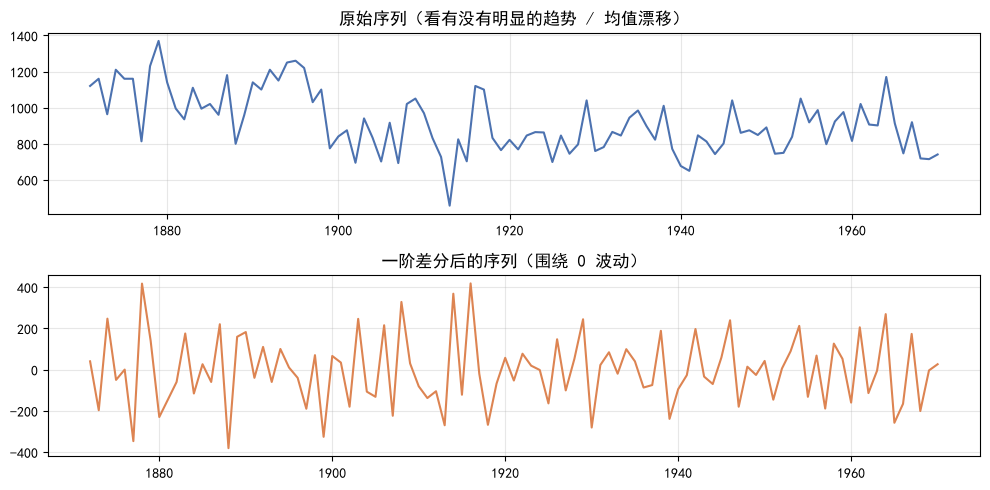

In [4]:
# 直观对比：原始序列 vs 一阶差分
fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].plot(series.index, series, color="#4C72B0")
axes[0].set_title("原始序列（看有没有明显的趋势 / 均值漂移）")
axes[1].plot(diff1.index, diff1, color="#DD8452")
axes[1].set_title("一阶差分后的序列（围绕 0 波动）")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 2. 定阶：确定 AR 阶数 p、MA 阶数 q

- **看图法**：$q$ 看 ACF（$q$ 阶后截尾）、$p$ 看 PACF（$p$ 阶后截尾）；差分后 ACF 衰减慢说明还没差分够
- **搜索法**（更客观）：枚举 $p, q$，取 **AIC 最小**的模型 —— AIC 同时惩罚残差平方和与参数个数，越小的模型在"拟合好"和"不过拟合"之间越平衡

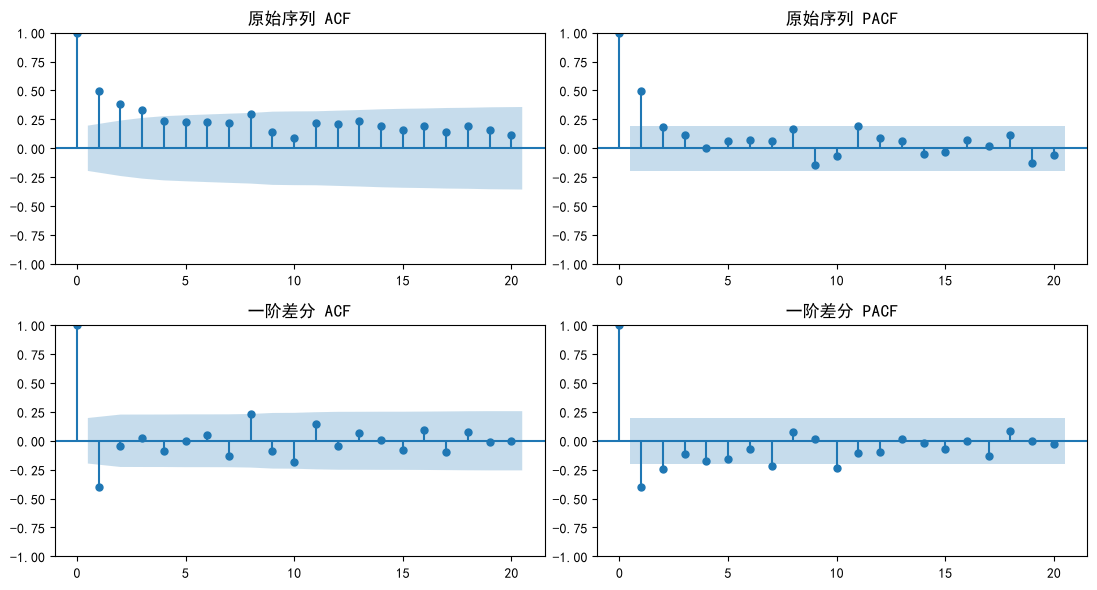

In [5]:
# ---------- 2.1 看图初判 ----------
# AR(p)：PACF 在 p 阶之后截尾；MA(q)：ACF 在 q 阶之后截尾
# 如果 ACF 衰减很慢（十几阶还很高），通常说明还需要继续差分
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
plot_acf(series, lags=20, ax=axes[0, 0], title="原始序列 ACF")
plot_pacf(series, lags=20, ax=axes[0, 1], title="原始序列 PACF", method="ywm")
plot_acf(diff1, lags=20, ax=axes[1, 0], title="一阶差分 ACF")
plot_pacf(diff1, lags=20, ax=axes[1, 1], title="一阶差分 PACF", method="ywm")
plt.tight_layout()
plt.show()

In [6]:
# ---------- 2.2 网格搜索 + AIC 定阶 ----------
def search_arima(s, max_p=3, max_d=2, max_q=3, verbose=True):
    """在给定范围内枚举 (p, d, q)，按 AIC 选出最优模型。

    参数
        s       : 待建模的时间序列（pd.Series，最好带频率，预测才能续上时间轴）
        max_p   : AR 项最大阶数
        max_d   : 差分次数最大阶数
        max_q   : MA 项最大阶数
        verbose : 是否打印前 10 名与拟合失败信息

    返回
        best  : dict，含最优 p/d/q、AIC/BIC 及拟合好的结果对象 model
        table : DataFrame，所有成功拟合的阶数按 AIC 升序排列
    """
    records = []
    for p in range(max_p + 1):
        for d in range(max_d + 1):
            for q in range(max_q + 1):
                # d = 0 时序列可能带非零均值，需要常数项 "c"；
                # d ≥ 1 时差分已消除均值，再加常数项会与差分项共线，所以用 "n"（无常数）
                trend = "c" if d == 0 else "n"
                try:
                    fit = ARIMA(s, order=(p, d, q), trend=trend).fit()
                except Exception as exc:  # 某些阶数不收敛或不可逆，跳过即可
                    if verbose:
                        print(f"  ARIMA({p},{d},{q}) 拟合失败，已跳过：{type(exc).__name__}")
                    continue
                records.append({"p": p, "d": d, "q": q, "AIC": fit.aic, "BIC": fit.bic, "model": fit})

    # 结果表（去掉不能放进 DataFrame 的 model 对象）
    table = pd.DataFrame([{k: v for k, v in r.items() if k != "model"} for r in records])
    table = table.sort_values("AIC").reset_index(drop=True)
    best = min(records, key=lambda r: r["AIC"])  # AIC 越小越好
    if verbose:
        print("按 AIC 排序的前 10 个模型：")
        print(table.head(10).to_string(index=False))
    return best, table

### 3. 拟合最优模型

`result.summary()` 里重点看：

- `ar.L1…` / `ma.L1…` 的 `P>|z|`：系数是否显著（$< 0.05$）
- `Ljung-Box (Q)` 的 `Prob(Q)`：残差是否白噪声（$> 0.05$ 为好）
- `Jarque-Bera (JB)` 的 `Prob(JB)`：残差是否近似正态
- `Heteroskedasticity (H)` 的 `Prob(H)`：残差方差是否恒定

In [7]:
# ---------- 3. 拟合最优模型 ----------
best, table = search_arima(series, max_p=3, max_d=2, max_q=3)
result = best["model"]                        # 已经拟合好的结果对象
order = (best["p"], best["d"], best["q"])
print(f"\n最优模型：ARIMA{order}   AIC = {best['AIC']:.2f}   BIC = {best['BIC']:.2f}")
print(result.summary())
# 提示：AIC 优先选的是“整体拟合 + 复杂度”最平衡的阶数，可能与 ADF 建议的 d 不同；
#       实务中若 ADF 已判定平稳，也可以把 d 固定为 ADF 的结果再比较 AIC

按 AIC 排序的前 10 个模型：
 p  d  q         AIC         BIC
 1  2  2 1264.243114 1274.582984
 0  2  3 1264.944857 1275.284726
 0  2  2 1265.824114 1273.579016
 2  2  2 1265.865943 1278.790780
 1  1  1 1267.218697 1275.004057
 2  2  3 1267.334725 1282.844530
 0  1  2 1267.918624 1275.703984
 2  1  1 1268.863460 1279.243939
 1  1  2 1268.885533 1279.266012
 0  1  1 1269.075413 1274.265653

最优模型：ARIMA(1, 2, 2)   AIC = 1264.24   BIC = 1274.58
                               SARIMAX Results                                
Dep. Variable:                 尼罗河年流量   No. Observations:                  100
Model:                 ARIMA(1, 2, 2)   Log Likelihood                -628.122
Date:                Sat, 07 Nov 2026   AIC                           1264.243
Time:                        20:15:42   BIC                           1274.583
Sample:                    01-01-1871   HQIC                          1268.425
                         - 01-01-1970                                         
Covariance T

### 4. 残差诊断

模型把所有"规律"都提取走了，剩下的残差就应该**只剩下随机噪声**：

- **Ljung–Box 检验**：$H_0$ = 残差无自相关，$p > 0.05$ 才算通过
- **残差 ACF 图**：柱子在蓝色阴影带内 ≈ 无显著自相关

Ljung-Box 检验（滞后 10 期）：
  lb_stat  lb_pvalue
14.088698   0.168984
结论：残差是白噪声 ✅ 模型可用于预测


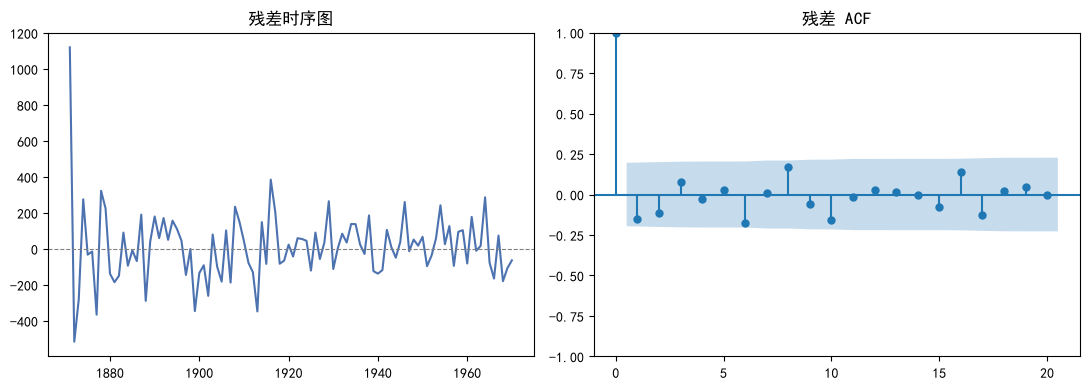

In [8]:
# ---------- 4. 残差诊断：好的模型残差应当像白噪声 ----------
resid = result.resid.dropna()  # 差分会让前几个观测没有残差，丢掉 NaN

# H0：残差不存在自相关（即白噪声）；p 值 > 0.05 表示不能拒绝 H0，残差可用
lb = acorr_ljungbox(resid, lags=[10], return_df=True)
print("Ljung-Box 检验（滞后 10 期）：")
print(lb.to_string(index=False))
print("结论：" + ("残差是白噪声 ✅ 模型可用于预测"
                if lb["lb_pvalue"].iloc[0] > 0.05 else "残差仍有自相关 ❌ 建议调整阶数"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(resid.index, resid, color="#4C72B0")
axes[0].axhline(0, color="gray", lw=0.8, ls="--")  # 0 参考线
axes[0].set_title("残差时序图")
plot_acf(resid, lags=20, ax=axes[1], title="残差 ACF")
plt.tight_layout()
plt.show()

### 5. 预测

`get_forecast(steps)` 返回点预测和置信区间；ARIMA 的置信区间随时间向外扩张（越远越不确定）。

1971-01-01    800.01
1972-01-01    813.29
1973-01-01    814.59
1974-01-01    812.83
1975-01-01    810.28
1976-01-01    807.53
1977-01-01    804.73
1978-01-01    801.92
1979-01-01    799.10
1980-01-01    796.28
Freq: YS-JAN


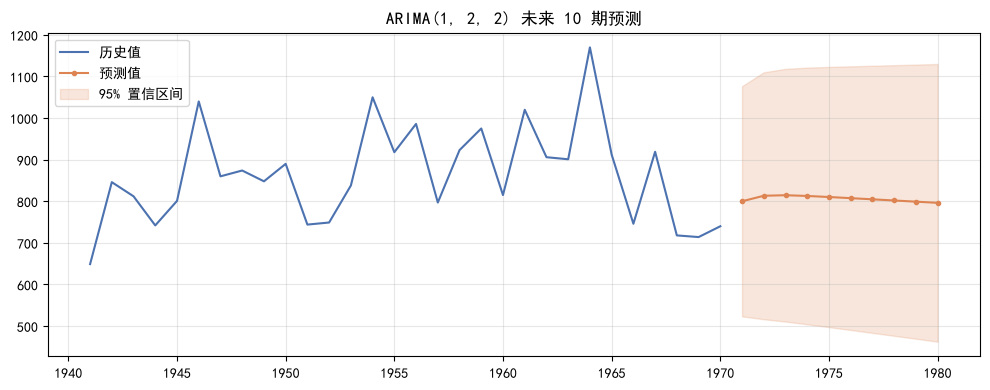

In [9]:
# ---------- 5. 预测未来 10 期 ----------
steps = 10
forecast = result.get_forecast(steps=steps)   # 预测对象：含点预测与置信区间
pred_mean = forecast.predicted_mean           # 点预测（条件均值）
pred_ci = forecast.conf_int(alpha=0.05)       # 95% 置信区间（alpha=0.05）

print(pred_mean.round(2).to_string())

plt.figure(figsize=(10, 4))
hist = series.iloc[-30:]                      # 只画最后 30 期，避免历史太长看不清
plt.plot(hist.index, hist, label="历史值", color="#4C72B0")
plt.plot(pred_mean.index, pred_mean, label="预测值", color="#DD8452", marker="o", ms=3)
plt.fill_between(pred_ci.index, pred_ci.iloc[:, 0], pred_ci.iloc[:, 1],
                 color="#DD8452", alpha=0.2, label="95% 置信区间")
plt.title(f"ARIMA{order} 未来 {steps} 期预测")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 6. 一键封装

把上面 1~5 步打包成一个函数：**ADF 自动定 $d$ → 网格搜索定 $p,q$ → 拟合 → 残差检验 → 预测**，换个序列直接调用即可。

In [10]:
# ---------- 6. 一键建模 ----------
def auto_arima(s, max_p=3, max_d=2, max_q=3, steps=10, verbose=True):
    """自动完成 ARIMA 建模：定 d → 定 p/q → 拟合 → 残差检验 → 预测。

    返回
        result      : 拟合好的 ARIMA 结果对象（可继续 .summary() / .plot_diagnostics()）
        order       : (p, d, q)
        forecast_df : DataFrame，列为 ["预测值", 下界, 上界]
    """
    # 1) 用 ADF 检验自动定差分次数：一直差分到平稳为止（最多 max_d 次）
    d, cur = 0, s.dropna()
    while d < max_d and adfuller(cur, autolag="AIC")[1] >= 0.05:
        cur = cur.diff().dropna()
        d += 1

    # 2) d 已由检验确定，只需在 p、q 上搜索，取 AIC 最小的组合
    best = None
    for p in range(max_p + 1):
        for q in range(max_q + 1):
            trend = "c" if d == 0 else "n"   # 同 search_arima：差分过的序列不用常数项
            try:
                fit = ARIMA(s, order=(p, d, q), trend=trend).fit()
            except Exception:
                continue                      # 不收敛的阶数直接跳过
            if best is None or fit.aic < best["AIC"]:
                best = {"p": p, "d": d, "q": q, "AIC": fit.aic, "model": fit}

    result = best["model"]
    order = (best["p"], best["d"], best["q"])

    # 3) 残差白噪声检验（滞后 10 期）
    lb_p = acorr_ljungbox(result.resid.dropna(), lags=[10], return_df=True)["lb_pvalue"].iloc[0]

    # 4) 未来 steps 期预测 + 95% 置信区间
    fc = result.get_forecast(steps=steps)
    forecast_df = fc.conf_int(alpha=0.05)
    forecast_df.insert(0, "预测值", fc.predicted_mean)   # 把点预测放到第一列

    if verbose:
        print(f"自动定阶结果：ARIMA{order}   AIC = {best['AIC']:.2f}")
        print(f"Ljung-Box p 值 = {lb_p:.4f} → " +
              ("残差白噪声 ✅" if lb_p > 0.05 else "残差仍有自相关 ❌"))
        print(forecast_df.round(2).to_string())
    return result, order, forecast_df


# 用法示例：换成自己的序列直接调
# result2, order2, fc2 = auto_arima(series, steps=10)